In [8]:

from pathlib import Path
from collections import Counter
import json
import zipfile
import html
import pandas as pd

ROOT = next(
    folder
    for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "data" / "divvy").is_dir()
)
OUT = ROOT / 'data/processed'
REPORTS = ROOT / 'reports'
CALENDAR = pd.date_range('2025-01-01', '2025-12-31', name='date')


def chart(path, title, series):
    width, height, left, top = 1100, 420, 85, 50
    plot_w, plot_h = 980, 300
    maximum = max(float(s.max()) for _, s, _ in series) or 1
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img"><title>{html.escape(title)}</title>', '<rect width="100%" height="100%" fill="white"/>', f'<text x="85" y="28" font-family="sans-serif" font-size="20">{html.escape(title)}</text>']
    for tick in range(5):
        y = top + plot_h * tick / 4
        value = maximum * (1 - tick / 4)
        parts += [f'<path d="M {left} {y} H {left+plot_w}" stroke="#ddd"/>', f'<text x="75" y="{y+5}" text-anchor="end" font-family="sans-serif" font-size="12">{value:,.0f}</text>']
    for i, (label, values, color) in enumerate(series):
        points = ' '.join(f'{left+j*plot_w/max(len(values)-1,1):.2f},{top+plot_h*(1-float(v)/maximum):.2f}' for j, v in enumerate(values) if pd.notna(v))
        parts += [f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2"/>', f'<text x="{left+i*260}" y="410" fill="{color}" font-family="sans-serif" font-size="14">{html.escape(label)}</text>']
    index = series[0][1].index
    for j in range(len(index)):
        if len(index) <= 12 or (hasattr(index[j], 'day') and index[j].day == 1):
            label = index[j].strftime('%b') if hasattr(index[j], 'strftime') else str(index[j])
            parts.append(f'<text x="{left+j*plot_w/max(len(index)-1,1):.2f}" y="375" text-anchor="middle" font-family="sans-serif" font-size="12">{label}</text>')
    parts.append('</svg>')
    path.write_text('\n'.join(parts))


def prepare_trips():
    counts, audit, seen, monthly = Counter(), Counter({k: 0 for k in ['raw_records', 'invalid_timestamp', 'outside_start_year', 'end_before_start', 'missing_ride_id', 'duplicate_valid_id', 'retained_trips']}), set(), []
    for month in range(1, 13):
        path = ROOT / f'data/divvy/2025{month:02d}-tripdata.csv.zip'
        if not path.exists():
            raise FileNotFoundError(f'Missing required month: {path}')
        before = audit.copy()
        with zipfile.ZipFile(path) as archive:
            members = [n for n in archive.namelist() if n.endswith('.csv') and not n.startswith('__MACOSX/')]
            if len(members) != 1:
                raise ValueError(f'Expected one CSV in {path.name}: {members}')
            with archive.open(members[0]) as source:
                for chunk in pd.read_csv(source, usecols=['ride_id', 'started_at', 'ended_at'], dtype='string', chunksize=100_000):
                    audit['raw_records'] += len(chunk)
                    start = pd.to_datetime(chunk.started_at, format='mixed', errors='coerce')
                    end = pd.to_datetime(chunk.ended_at, format='mixed', errors='coerce')
                    invalid = start.isna() | end.isna()
                    audit['invalid_timestamp'] += int(invalid.sum())
                    outside = ~invalid & ((start < '2025-01-01') | (start >= '2026-01-01'))
                    audit['outside_start_year'] += int(outside.sum())
                    reversed_time = ~invalid & ~outside & (end < start)
                    audit['end_before_start'] += int(reversed_time.sum())
                    missing_id = ~invalid & ~outside & ~reversed_time & (chunk.ride_id.isna() | chunk.ride_id.str.strip().eq(''))
                    audit['missing_ride_id'] += int(missing_id.sum())
                    keep = ~(invalid | outside | reversed_time | missing_id)
                    for ride_id, date in zip(chunk.loc[keep, 'ride_id'], start[keep].dt.strftime('%Y-%m-%d')):
                        if ride_id in seen:
                            audit['duplicate_valid_id'] += 1
                            continue
                        seen.add(ride_id)
                        counts[date] += 1
                        audit['retained_trips'] += 1
        monthly.append({'file': path.name, **{k: audit[k] - before[k] for k in audit}})
        print(f'Processed {path.name}', flush=True)
    daily = pd.Series(counts, name='total_rides')
    daily.index = pd.to_datetime(daily.index)
    daily = daily.reindex(CALENDAR).to_frame()
    # Missing dates stay missing rather than silently becoming zero rides.
    audit['missing_ridership_dates'] = int(daily.total_rides.isna().sum())
    assert daily.total_rides.sum() == audit['retained_trips']
    exclusions = ['invalid_timestamp', 'outside_start_year', 'end_before_start', 'missing_ride_id', 'duplicate_valid_id']
    assert audit['raw_records'] == audit['retained_trips'] + sum(audit[k] for k in exclusions)
    pd.DataFrame(monthly).to_csv(OUT / 'trip_quality_by_month.csv', index=False)
    return daily, dict(audit)


def prepare_weather():
    path = ROOT / 'data/2025-chicago-weather.csv'
    metadata = pd.read_csv(path, nrows=1).iloc[0].to_dict()
    weather = pd.read_csv(path, skiprows=3)
    required = ['time', 'temperature_2m (°C)', 'rain (mm)', 'snowfall (cm)']
    if not set(required).issubset(weather.columns):
        raise ValueError(f'Unexpected weather columns: {weather.columns.tolist()}')
    timestamp = pd.to_datetime(weather.time, errors='coerce')
    if timestamp.isna().any() or timestamp.duplicated().any():
        raise ValueError('Weather has invalid or duplicate hourly timestamps; investigate before merging.')
    for column in required[1:]:
        weather[column] = pd.to_numeric(weather[column], errors='coerce')
    weather['date'] = timestamp.dt.normalize()
    weather['hour'] = timestamp.dt.hour
    weather = weather[(weather.date >= '2025-01-01') & (weather.date < '2026-01-01')]
    grouped = weather.groupby('date')
    daily = grouped.agg(temperature_mean_c=('temperature_2m (°C)', 'mean'), rain_mm=('rain (mm)', lambda s: s.sum(min_count=24)), snowfall_cm=('snowfall (cm)', lambda s: s.sum(min_count=24)), weather_hours=('hour', 'nunique'))
    complete_temperature = grouped['temperature_2m (°C)'].count().eq(24)
    daily.loc[~complete_temperature, 'temperature_mean_c'] = float('nan')
    metadata.update(hourly_rows_2025=len(weather), incomplete_days=int(daily.weather_hours.ne(24).sum()), missing_dates=int(len(CALENDAR.difference(daily.index))))
    return daily, metadata


def main():
    OUT.mkdir(parents=True, exist_ok=True)
    (REPORTS / 'figures').mkdir(parents=True, exist_ok=True)
    daily, audit = prepare_trips()
    weather, metadata = prepare_weather()
    merged = daily.join(weather, how='left', validate='one_to_one')
    assert len(merged) == 365 and merged.index.is_unique
    audit['weather_unmatched_dates'] = int(merged.weather_hours.isna().sum())
    audit['missing_weather_values'] = merged[['temperature_mean_c', 'rain_mm', 'snowfall_cm']].isna().sum().to_dict()
    daily.to_csv(OUT / 'daily_ridership_2025.csv', index_label='date')
    weather.to_csv(OUT / 'daily_weather_2025.csv', index_label='date')
    merged.to_csv(OUT / 'daily_ridership_weather_2025.csv', index_label='date')
    monthly = daily.total_rides.groupby(daily.index.month).mean()
    monthly.index = pd.Index([pd.Timestamp(2025, int(m), 1).strftime('%b') for m in monthly.index])
    monthly.rename('mean_daily_rides').to_csv(OUT / 'monthly_mean_ridership_2025.csv', index_label='month')
    chart(REPORTS / 'figures/daily_ridership_2025.svg', 'Divvy ridership, 2025 — rides per day', [('Daily rides', daily.total_rides, '#a9bdcc'), ('7-day trailing mean', daily.total_rides.rolling(7).mean(), '#006c76')])
    chart(REPORTS / 'figures/monthly_ridership_2025.svg', 'Divvy monthly average — rides per day', [('Monthly mean', monthly, '#006c76')])
    (REPORTS / 'data_quality.json').write_text(json.dumps({'trips': audit, 'weather_metadata': metadata}, indent=2, default=str))
    rows = '\n'.join(f'| {k} | {v:,} |' for k, v in audit.items() if isinstance(v, int))
    peak, low = daily.total_rides.idxmax(), daily.total_rides.idxmin()
    report = f'''# November 19 milestone: Divvy ridership

## Data quality
| Check | Count |
| --- | ---: |
{rows}

Exclusions are sequential: invalid timestamps, starts outside 2025, end before start, missing ID, then duplicate otherwise-valid ID. Zero-duration rides are retained. Missing station details are not grounds for exclusion. Missing calendar dates remain missing rather than becoming zero.

## Findings
Peak daily ridership: {peak.date()} ({daily.loc[peak, 'total_rides']:,.0f} rides).
Lowest daily ridership: {low.date()} ({daily.loc[low, 'total_rides']:,.0f} rides).
Highest monthly mean: {monthly.idxmax()} ({monthly.max():,.0f} rides/day).
One year cannot establish a repeating seasonal pattern or prove weather causes changes.

## Weather and date alignment
Trip start timestamps are treated as Chicago local wall-clock values; source confirmation remains necessary. Weather comes from the existing hourly export, described as Open-Meteo in the README. Temperature is averaged in Celsius; rain is summed in mm and snowfall in cm. Rain is not total precipitation. Complete daily values require 24 nonmissing hourly observations.
Weather metadata: {metadata}.
Missing merged weather values: {audit['missing_weather_values']}.
The fixed UTC offset in the export requires checking against Chicago daylight-saving time. This merge is provisional until date alignment and original source request are confirmed.

## Baseline plan
Predict each day using rides on the same weekday of the previous week. Use a chronological holdout, provisionally October through December, and evaluate seven-day blocks using only data available at each issue date. Report MAE, RMSE and mean signed error on identical evaluation dates. No random split. Observed future weather is unavailable at forecast time.
'''
    (REPORTS / 'milestone_nov19.md').write_text(report)
    print(json.dumps(audit, indent=2))
    print(f'Outputs saved in: {OUT}')
    return merged


merged = main()
display(merged.head())


Processed 202501-tripdata.csv.zip
Processed 202502-tripdata.csv.zip
Processed 202503-tripdata.csv.zip
Processed 202504-tripdata.csv.zip
Processed 202505-tripdata.csv.zip
Processed 202506-tripdata.csv.zip
Processed 202507-tripdata.csv.zip
Processed 202508-tripdata.csv.zip
Processed 202509-tripdata.csv.zip
Processed 202510-tripdata.csv.zip
Processed 202511-tripdata.csv.zip
Processed 202512-tripdata.csv.zip
{
  "raw_records": 5552994,
  "invalid_timestamp": 0,
  "outside_start_year": 53,
  "end_before_start": 29,
  "missing_ride_id": 0,
  "duplicate_valid_id": 0,
  "retained_trips": 5552912,
  "missing_ridership_dates": 0,
  "weather_unmatched_dates": 0,
  "missing_weather_values": {
    "temperature_mean_c": 0,
    "rain_mm": 0,
    "snowfall_cm": 0
  }
}
Outputs saved in: /Users/mainguyenhong/Divvy_Forecasting_Project3/data/processed


,total_rides,temperature_mean_c,rain_mm,snowfall_cm,weather_hours
date,,,,,
2025-01-01,3562,-1.329167,0.0,0.07,24
2025-01-02,4749,-2.433333,0.0,0.14,24
2025-01-03,4200,-5.116667,0.0,0.00,24
2025-01-04,3198,-7.991667,0.0,0.00,24
2025-01-05,2933,-6.391667,0.1,0.35,24


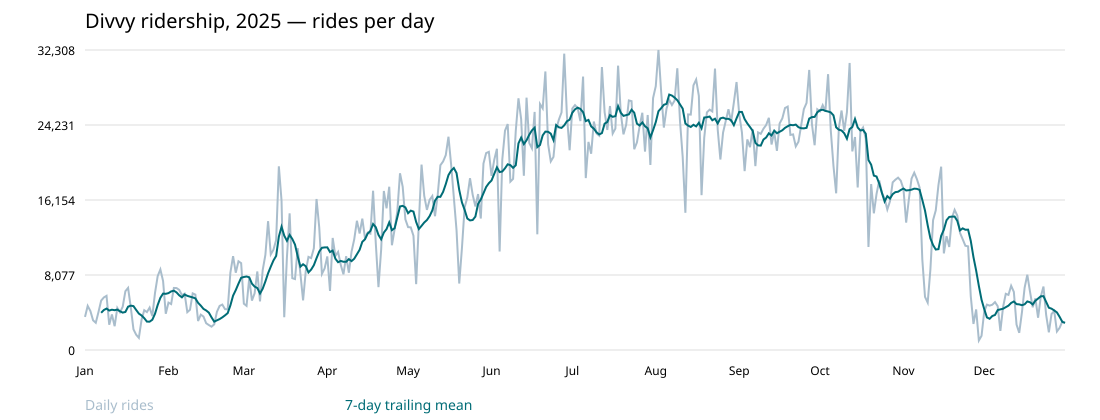

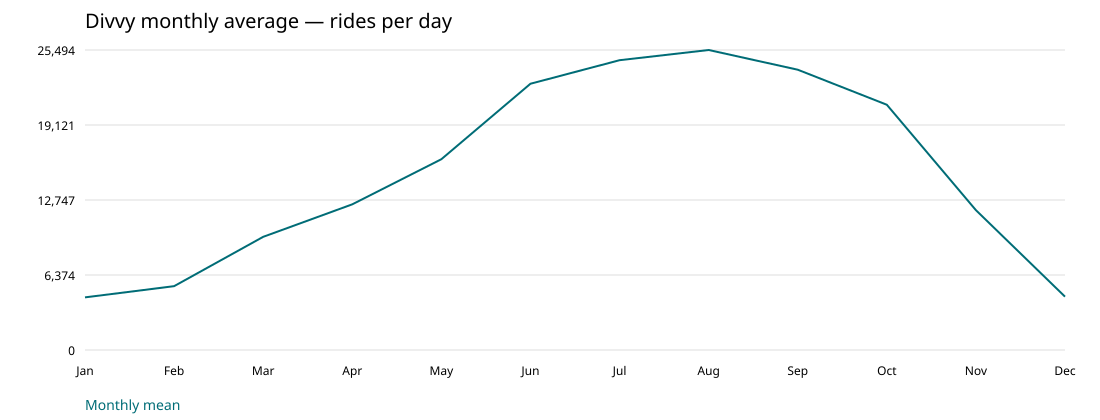

In [9]:
from IPython.display import SVG, display

# Daily rides and a 7-day rolling average.
display(SVG(filename=str(
    REPORTS / "figures/daily_ridership_2025.svg"
)))

# Average daily rides for each month.
display(SVG(filename=str(
    REPORTS / "figures/monthly_ridership_2025.svg"
)))
